# ILD
Extracting the interaural level difference wont allow us to determine the angle of arrival properly. If HRTF information was available, a mix of level dofference, frequency response and time difference could be used to accurately predict angles arriving to the HATS system. Instead here I will plot the ILD by angle, more to show the results in the paper, and to explain how it works. Ideally ILD should be lowest in the centre, and as the angles grow on either side, the ILD should get higher.

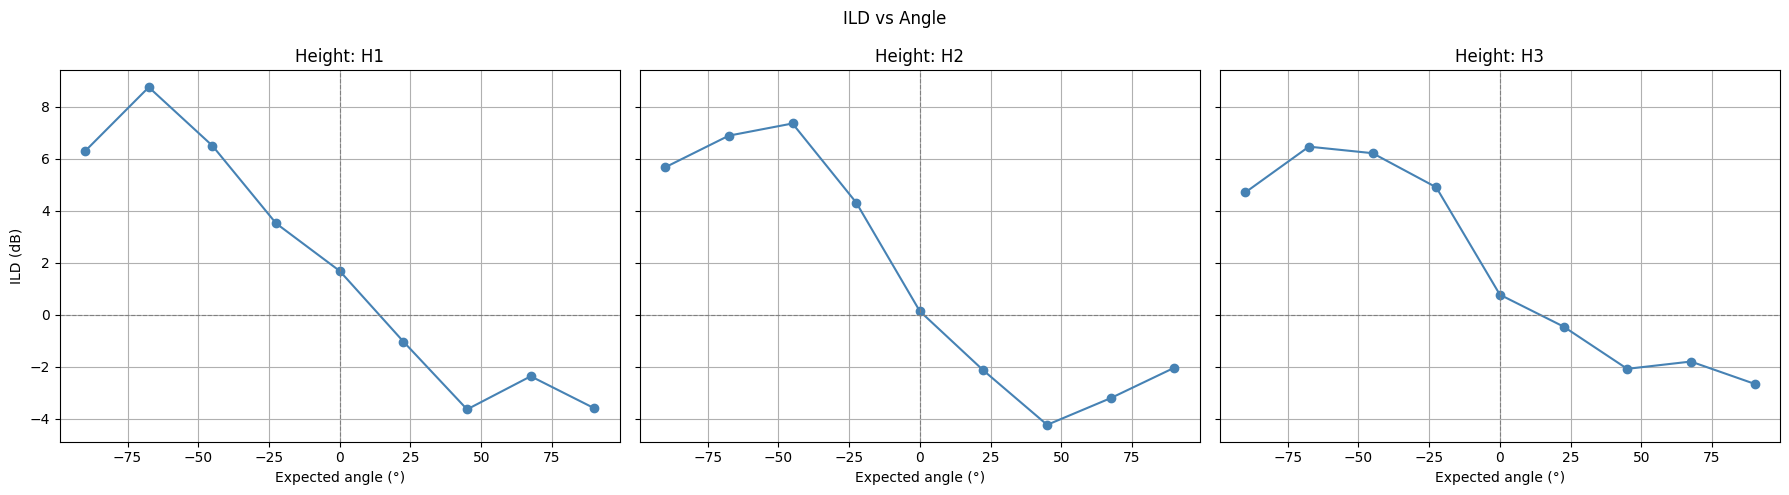

In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
heights = ["H1", "H2", "H3"]  
PathToFiles = "../Audio_Files/HATS/"

recordings = {}

for height in heights:
    recordings[height] = {}
    for angle in angles:
        folder = Path(PathToFiles) / str(height) / str(angle)
        
        if folder.is_dir():
            recordings[height][angle] = {
                'L': folder / "L.wav",
                'R': folder / "R.wav"
            }
        else:
            print(f"Missing folder: {folder}")


fig, axes = plt.subplots(1, len(recordings), figsize=(6*len(recordings), 5), sharey=True)

if len(recordings) == 1:
    axes = [axes]

for ax, (height, angle_dict) in zip(axes, recordings.items()):
    angles = []
    ilds = []
    
    for angle, files in sorted(angle_dict.items(), key=lambda x: float(x[0])):
        dataL, fs = sf.read(files['L'])
        dataR, fs = sf.read(files['R'])
        
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
        
        L_Trimmed = dataL[L_click_idx + int(fs*2):]
        R_Trimmed = dataR[R_click_idx + int(fs*2):]
        
        min_len = min(len(L_Trimmed), len(R_Trimmed))
        L_Trimmed = L_Trimmed[:min_len]
        R_Trimmed = R_Trimmed[:min_len]
        
        rms_L = np.sqrt(np.mean(L_Trimmed**2))
        rms_R = np.sqrt(np.mean(R_Trimmed**2))
        ild = 20 * np.log10(rms_L / (rms_R + 1e-12))
        
        angles.append(float(angle))
        ilds.append(ild)
    
    ax.plot(angles, ilds, 'o-', color='steelblue')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_xlabel('Expected angle (°)')
    ax.set_title(f'Height: {height}')
    ax.grid(True)

axes[0].set_ylabel('ILD (dB)')
plt.suptitle('ILD vs Angle')
plt.tight_layout()
plt.show()
